In [1]:
# ============================================================
# CELL 1: IMPORT LIBRARIES
# Mục đích: Import các thư viện phục vụ Machine Learning
# ============================================================

# Pandas: xử lý dữ liệu dạng bảng
import pandas as pd

# NumPy: xử lý dữ liệu số và mảng
import numpy as np

# Matplotlib: vẽ biểu đồ
import matplotlib.pyplot as plt

# Seaborn: trực quan hóa dữ liệu
import seaborn as sns

# Path: xử lý đường dẫn file
from pathlib import Path

# Pipeline: kết hợp các bước preprocessing và model
from sklearn.pipeline import Pipeline

# ColumnTransformer: xử lý các loại dữ liệu khác nhau
from sklearn.compose import ColumnTransformer

# Chia dataset thành train và test
from sklearn.model_selection import train_test_split

# Chuẩn hóa dữ liệu số
from sklearn.preprocessing import StandardScaler

# Mã hóa dữ liệu dạng chữ
from sklearn.preprocessing import OneHotEncoder

# Logistic Regression
from sklearn.linear_model import LogisticRegression

# Các metrics đánh giá mô hình
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    RocCurveDisplay,
    PrecisionRecallDisplay
)

# Lưu mô hình
import joblib

# Kiểm tra phiên bản thư viện
import sklearn

print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)

print("Libraries imported successfully!")

Pandas: 3.1.1
Scikit-learn: 1.9.1
Libraries imported successfully!


In [2]:
# ============================================================
# CELL 2: LOAD DATASET
# Mục đích: Đọc dataset gốc cho Machine Learning
# ============================================================

# Xác định thư mục gốc dự án
PROJECT_DIR = Path.cwd().parent

# Đường dẫn đến file CSV
DATA_PATH = (
    PROJECT_DIR
    / "dataset"
    / "WA_Fn-UseC_-HR-Employee-Attrition.csv"
)

# Kiểm tra dataset có tồn tại hay không
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Không tìm thấy dataset: {DATA_PATH}"
    )

# Đọc dataset
df = pd.read_csv(DATA_PATH)

# Hiển thị kích thước dữ liệu
print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

# Hiển thị dữ liệu mẫu
display(df.head())

Dataset loaded successfully!
Dataset shape: (1470, 35)


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [3]:
# ============================================================
# CELL 3: REMOVE UNNECESSARY FEATURES
# Mục đích: Loại bỏ các cột không có giá trị dự báo hữu ích
# ============================================================

# Tạo bản sao dữ liệu để không ảnh hưởng đến dataset gốc
df_clean = df.copy()

# Danh sách cột cần loại bỏ
columns_to_drop = [
    "EmployeeNumber",
    "EmployeeCount",
    "Over18",
    "StandardHours"
]

# Chỉ xóa những cột thực sự tồn tại
columns_to_drop = [
    col for col in columns_to_drop
    if col in df_clean.columns
]

# Loại bỏ các cột
df_clean = df_clean.drop(columns=columns_to_drop)

# Hiển thị kết quả
print("Removed columns:", columns_to_drop)
print("Dataset shape after cleaning:", df_clean.shape)

display(df_clean.head())

Removed columns: ['EmployeeNumber', 'EmployeeCount', 'Over18', 'StandardHours']
Dataset shape after cleaning: (1470, 31)


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EnvironmentSatisfaction,Gender,...,PerformanceRating,RelationshipSatisfaction,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,2,Female,...,3,1,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,3,Male,...,4,4,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,4,Male,...,3,2,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,4,Female,...,3,3,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,Male,...,3,4,1,6,3,3,2,2,2,2


In [4]:
# ============================================================
# CELL 4: SPLIT FEATURES AND TARGET
# Mục đích: Tách dữ liệu đầu vào X và dữ liệu mục tiêu y
# ============================================================

# Tên biến mục tiêu
TARGET = "Attrition"

# X: chứa tất cả features ngoại trừ Attrition
X = df_clean.drop(columns=[TARGET])

# y: chứa trạng thái nghỉ việc
y = df_clean[TARGET].map({
    "No": 0,
    "Yes": 1
})

# Kiểm tra dữ liệu
print("Features shape:", X.shape)
print("Target shape:", y.shape)

# Kiểm tra phân bố của target
print("\nTarget distribution:")
print(y.value_counts())

# Kiểm tra tỷ lệ phần trăm
print("\nTarget percentage:")
print((y.value_counts(normalize=True) * 100).round(2))

Features shape: (1470, 30)
Target shape: (1470,)

Target distribution:
Attrition
0    1233
1     237
Name: count, dtype: int64

Target percentage:
Attrition
0    83.88
1    16.12
Name: proportion, dtype: float64


In [5]:
# ============================================================
# CELL 5: TRAIN-TEST SPLIT
# Mục đích: Tạo tập dữ liệu huấn luyện và kiểm tra
# ============================================================

# Chia dữ liệu
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,      # 20% dữ liệu dành cho test
    random_state=42,    # Cố định kết quả chia dữ liệu
    stratify=y         # Giữ tỷ lệ các lớp
)

# Kiểm tra kích thước
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

# Kiểm tra tỷ lệ Attrition trên tập train
print("\nTrain target distribution (%):")
print((y_train.value_counts(normalize=True) * 100).round(2))

# Kiểm tra tỷ lệ Attrition trên tập test
print("\nTest target distribution (%):")
print((y_test.value_counts(normalize=True) * 100).round(2))

X_train: (1176, 30)
X_test: (294, 30)
y_train: (1176,)
y_test: (294,)

Train target distribution (%):
Attrition
0    83.84
1    16.16
Name: proportion, dtype: float64

Test target distribution (%):
Attrition
0    84.01
1    15.99
Name: proportion, dtype: float64


In [6]:
# ============================================================
# CELL 6: PREPROCESSING FOR LOGISTIC REGRESSION
# Mục đích: Xây dựng pipeline xử lý dữ liệu đầu vào
# ============================================================

# Tự động lấy danh sách cột categorical từ training set
categorical_features = X_train.select_dtypes(
    include=["object"]
).columns.tolist()

# Tự động lấy danh sách cột numerical từ training set
numerical_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

print("Categorical features:", categorical_features)
print("\nNumerical features:", numerical_features)

# OneHotEncoder:
# Chuyển dữ liệu categorical thành các cột số
# handle_unknown="ignore" tránh lỗi category lạ trong test
# sparse_output=False trả về array thông thường
categorical_transformer = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

# StandardScaler:
# Chuẩn hóa numerical features
numerical_transformer = StandardScaler()

# ColumnTransformer:
# Áp dụng encoder cho categorical
# Áp dụng scaler cho numerical
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            categorical_transformer,
            categorical_features
        ),
        (
            "numerical",
            numerical_transformer,
            numerical_features
        )
    ]
)

# Kiểm tra preprocessing
print("\nPreprocessor created successfully!")

Categorical features: ['BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'OverTime']

Numerical features: ['Age', 'DailyRate', 'DistanceFromHome', 'Education', 'EnvironmentSatisfaction', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobSatisfaction', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']

Preprocessor created successfully!


C:\Users\WINDOWS\AppData\Local\Temp\ipykernel_4040\863116576.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X_train.select_dtypes(


In [7]:
# ============================================================
# CELL 7: BUILD LOGISTIC REGRESSION
# Mục đích: Tạo pipeline gồm preprocessing và Logistic Regression
# ============================================================

# Tạo pipeline
logistic_model = Pipeline(
    steps=[
        # Bước 1: Encoding và scaling
        ("preprocessing", preprocessor),

        # Bước 2: Huấn luyện Logistic Regression
        (
            "classifier",
            LogisticRegression(
                max_iter=1000,
                random_state=42
            )
        )
    ]
)

# Hiển thị cấu trúc model
print(logistic_model)

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('categorical',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['BusinessTravel',
                                                   'Department',
                                                   'EducationField', 'Gender',
                                                   'JobRole', 'MaritalStatus',
                                                   'OverTime']),
                                                 ('numerical', StandardScaler(),
                                                  ['Age', 'DailyRate',
                                                   'DistanceFromHome',
                                                   'Education',
                                                   'EnvironmentSatisfaction',
    

In [8]:
# ============================================================
# CELL 8: TRAIN LOGISTIC REGRESSION
# Mục đích: Huấn luyện model bằng dữ liệu training
# ============================================================

# Fit model trên tập train
logistic_model.fit(
    X_train,
    y_train
)

print("Logistic Regression training completed!")

Logistic Regression training completed!


In [9]:
# ============================================================
# CELL 9: EVALUATE LOGISTIC REGRESSION
# Mục đích: Đánh giá hiệu suất của Logistic Regression
# ============================================================

# Dự đoán nhãn trên test set
y_pred_logistic = logistic_model.predict(X_test)

# Dự đoán xác suất nghỉ việc
# Cột index 1 tương ứng class = 1 (Attrition = Yes)
y_prob_logistic = logistic_model.predict_proba(X_test)[:, 1]

# Tính Accuracy
accuracy_logistic = accuracy_score(
    y_test,
    y_pred_logistic
)

# Tính Precision
precision_logistic = precision_score(
    y_test,
    y_pred_logistic,
    zero_division=0
)

# Tính Recall
recall_logistic = recall_score(
    y_test,
    y_pred_logistic,
    zero_division=0
)

# Tính F1-score
f1_logistic = f1_score(
    y_test,
    y_pred_logistic,
    zero_division=0
)

# Tính ROC-AUC dựa trên xác suất dự đoán
roc_auc_logistic = roc_auc_score(
    y_test,
    y_prob_logistic
)

# Tính PR-AUC (Average Precision)
pr_auc_logistic = average_precision_score(
    y_test,
    y_prob_logistic
)

# In kết quả
print("=" * 50)
print("LOGISTIC REGRESSION EVALUATION")
print("=" * 50)

print(f"Accuracy : {accuracy_logistic:.4f}")
print(f"Precision: {precision_logistic:.4f}")
print(f"Recall  : {recall_logistic:.4f}")
print(f"F1-score: {f1_logistic:.4f}")
print(f"ROC-AUC : {roc_auc_logistic:.4f}")
print(f"PR-AUC : {pr_auc_logistic:.4f}")

LOGISTIC REGRESSION EVALUATION
Accuracy : 0.8605
Precision: 0.6154
Recall  : 0.3404
F1-score: 0.4384
ROC-AUC : 0.8115
PR-AUC : 0.5836


Logistic Regression Confusion Matrix:
[[237  10]
 [ 31  16]]


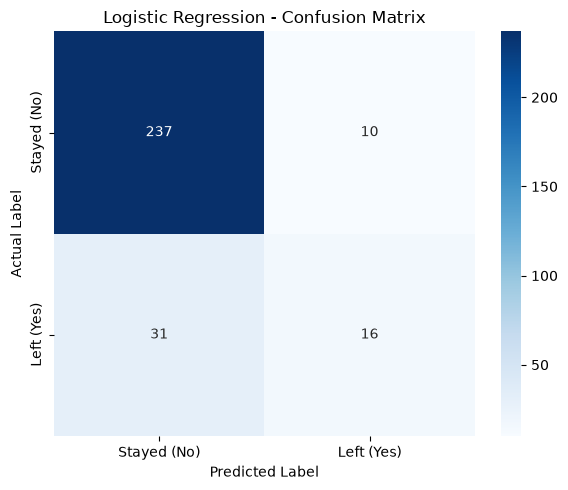

In [10]:
# ============================================================
# CELL 10: CONFUSION MATRIX - LOGISTIC REGRESSION
# Mục đích: Quan sát số lượng dự đoán đúng và sai
# ============================================================

# Tạo Confusion Matrix
cm_logistic = confusion_matrix(
    y_test,
    y_pred_logistic
)

# In ma trận
print("Logistic Regression Confusion Matrix:")
print(cm_logistic)

# Vẽ Heatmap
plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_logistic,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Stayed (No)", "Left (Yes)"],
    yticklabels=["Stayed (No)", "Left (Yes)"]
)

plt.title("Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.tight_layout()
plt.show()

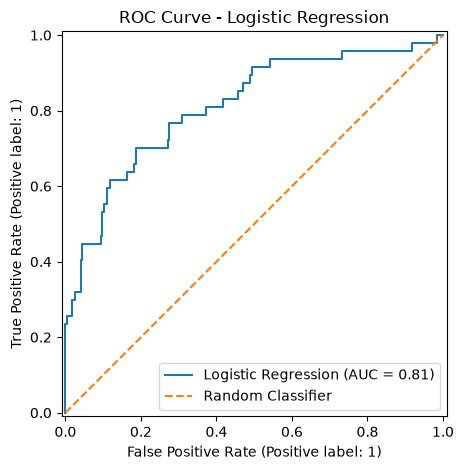

In [11]:
# ============================================================
# CELL 11: ROC CURVE - LOGISTIC REGRESSION
# Mục đích: Đánh giá khả năng phân biệt giữa hai lớp
# ============================================================

# Vẽ ROC Curve từ mô hình Logistic Regression
RocCurveDisplay.from_predictions(
    y_test,
    y_prob_logistic,
    name="Logistic Regression"
)

# Đường chéo biểu thị mô hình phân loại ngẫu nhiên
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.title("ROC Curve - Logistic Regression")
plt.legend()

plt.tight_layout()
plt.show()

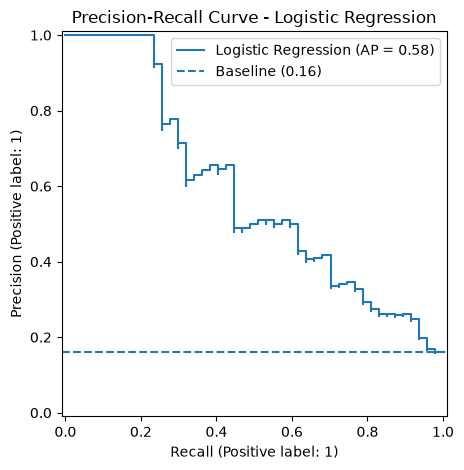

In [12]:
# ============================================================
# CELL 12: PRECISION-RECALL CURVE - LOGISTIC REGRESSION
# Mục đích: Đánh giá khả năng phát hiện lớp nghỉ việc
# ============================================================

# Vẽ Precision-Recall Curve
PrecisionRecallDisplay.from_predictions(
    y_test,
    y_prob_logistic,
    name="Logistic Regression"
)

# Đường baseline tương ứng với tỷ lệ positive trong tập test
baseline_rate = y_test.mean()

plt.axhline(
    y=baseline_rate,
    linestyle="--",
    label=f"Baseline ({baseline_rate:.2f})"
)

plt.title("Precision-Recall Curve - Logistic Regression")
plt.legend()

plt.tight_layout()
plt.show()

In [13]:
# ============================================================
# CELL 13: IMPORT CATBOOST
# Mục đích: Import thư viện CatBoost để xây dựng mô hình
# ============================================================

# CatBoostClassifier:
# Thuật toán Gradient Boosting dùng cho bài toán phân loại
from catboost import CatBoostClassifier

print("CatBoost imported successfully!")

CatBoost imported successfully!


In [14]:
# ============================================================
# CELL 14: PREPARE DATA FOR CATBOOST
# Mục đích: Chuẩn bị categorical features ở dạng dữ liệu gốc
# ============================================================

# Tạo bản sao dữ liệu train
X_train_cat = X_train.copy()

# Tạo bản sao dữ liệu test
X_test_cat = X_test.copy()

# Lấy danh sách cột categorical
cat_features = X_train_cat.select_dtypes(
    include=["object"]
).columns.tolist()

# Chuyển các categorical features về kiểu string
# Điều này giúp CatBoost xử lý category ổn định
for column in cat_features:

    # Chuyển kiểu dữ liệu train thành string
    X_train_cat[column] = X_train_cat[column].astype(str)

    # Chuyển kiểu dữ liệu test thành string
    X_test_cat[column] = X_test_cat[column].astype(str)

# Hiển thị danh sách categorical features
print("CatBoost categorical features:")
print(cat_features)

print("\nTrain shape:", X_train_cat.shape)
print("Test shape:", X_test_cat.shape)

# Hiển thị dữ liệu mẫu
display(X_train_cat.head())

CatBoost categorical features:
['BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'OverTime']

Train shape: (1176, 30)
Test shape: (294, 30)


C:\Users\WINDOWS\AppData\Local\Temp\ipykernel_4040\2877252492.py:13: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_features = X_train_cat.select_dtypes(


,Age,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EnvironmentSatisfaction,Gender,HourlyRate,...,PerformanceRating,RelationshipSatisfaction,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
1194,47,Travel_Rarely,1225,Sales,2,4,Life Sciences,2,Female,47,...,3,3,3,29,2,3,3,2,1,2
128,22,Travel_Rarely,594,Research & Development,2,1,Technical Degree,3,Male,100,...,3,3,1,3,2,3,2,1,2,1
810,46,Travel_Rarely,406,Sales,3,1,Marketing,1,Male,52,...,3,4,1,23,3,3,12,9,4,9
478,25,Travel_Rarely,622,Sales,13,1,Medical,2,Male,40,...,3,3,0,7,1,3,7,4,0,6
491,43,Travel_Frequently,1001,Research & Development,9,5,Medical,4,Male,72,...,3,2,1,10,3,3,8,7,4,7


In [15]:
# ============================================================
# CELL 15: BUILD CATBOOST MODEL
# Mục đích: Khởi tạo mô hình CatBoost Classifier
# ============================================================

catboost_model = CatBoostClassifier(
    iterations=500,             # Số vòng xây dựng cây
    depth=6,                   # Độ sâu của mỗi cây
    learning_rate=0.03,         # Tốc độ học
    loss_function="Logloss",    # Hàm loss cho binary classification
    eval_metric="AUC",          # Metric theo dõi khi huấn luyện
    random_seed=42,            # Cố định random seed
    verbose=100,               # In log sau mỗi 100 iterations
    allow_writing_files=False  # Không tạo file log mặc định
)

print("CatBoost model created!")

CatBoost model created!


In [16]:
# ============================================================
# CELL 16: TRAIN CATBOOST
# Mục đích: Huấn luyện CatBoost trên tập dữ liệu train
# ============================================================

# Huấn luyện model
# cat_features: chỉ định các cột categorical
catboost_model.fit(
    X_train_cat,
    y_train,
    cat_features=cat_features
)

print("CatBoost training completed!")

0:	total: 196ms	remaining: 1m 37s
100:	total: 4.46s	remaining: 17.6s
200:	total: 9.21s	remaining: 13.7s
300:	total: 13.4s	remaining: 8.88s
400:	total: 17.8s	remaining: 4.39s
499:	total: 22.1s	remaining: 0us
CatBoost training completed!


In [17]:
# ============================================================
# CELL 17: EVALUATE CATBOOST
# Mục đích: Đánh giá khả năng dự đoán của CatBoost
# ============================================================

# Dự đoán nhãn trên test
y_pred_catboost = catboost_model.predict(
    X_test_cat
)

# Chuyển kết quả về mảng số nguyên 0 và 1
y_pred_catboost = np.asarray(
    y_pred_catboost
).reshape(-1).astype(int)

# Dự đoán xác suất
# Lấy cột 1 tương ứng xác suất nghỉ việc
y_prob_catboost = catboost_model.predict_proba(
    X_test_cat
)[:, 1]

# Tính Accuracy
accuracy_catboost = accuracy_score(
    y_test,
    y_pred_catboost
)

# Tính Precision
precision_catboost = precision_score(
    y_test,
    y_pred_catboost,
    zero_division=0
)

# Tính Recall
recall_catboost = recall_score(
    y_test,
    y_pred_catboost,
    zero_division=0
)

# Tính F1-score
f1_catboost = f1_score(
    y_test,
    y_pred_catboost,
    zero_division=0
)

# Tính ROC-AUC
roc_auc_catboost = roc_auc_score(
    y_test,
    y_prob_catboost
)

# Tính PR-AUC
pr_auc_catboost = average_precision_score(
    y_test,
    y_prob_catboost
)

# Hiển thị kết quả
print("=" * 50)
print("CATBOOST EVALUATION")
print("=" * 50)

print(f"Accuracy : {accuracy_catboost:.4f}")
print(f"Precision: {precision_catboost:.4f}")
print(f"Recall  : {recall_catboost:.4f}")
print(f"F1-score: {f1_catboost:.4f}")
print(f"ROC-AUC : {roc_auc_catboost:.4f}")
print(f"PR-AUC : {pr_auc_catboost:.4f}")


# ============================================================
# CELL 17.1: CATBOOST CLASSIFICATION REPORT
# Mục đích: Đánh giá hiệu suất trên từng lớp
# ============================================================

print(
    classification_report(
        y_test,
        y_pred_catboost,
        target_names=["Stayed (No)", "Left (Yes)"],
        zero_division=0
    )
)

CATBOOST EVALUATION
Accuracy : 0.8537
Precision: 0.6667
Recall  : 0.1702
F1-score: 0.2712
ROC-AUC : 0.8118
PR-AUC : 0.5327
              precision    recall  f1-score   support

 Stayed (No)       0.86      0.98      0.92       247
  Left (Yes)       0.67      0.17      0.27        47

    accuracy                           0.85       294
   macro avg       0.76      0.58      0.59       294
weighted avg       0.83      0.85      0.82       294



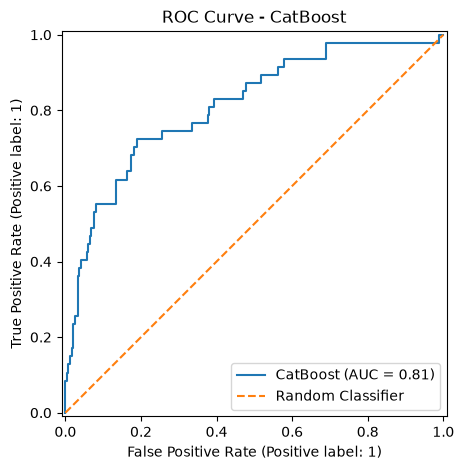

In [18]:
# ============================================================
# CELL 19: CATBOOST ROC CURVE
# Mục đích: Đánh giá khả năng phân biệt hai lớp của CatBoost
# ============================================================

# Vẽ ROC Curve
RocCurveDisplay.from_predictions(
    y_test,
    y_prob_catboost,
    name="CatBoost"
)

# Đường tham chiếu của mô hình ngẫu nhiên
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.title("ROC Curve - CatBoost")
plt.legend()

plt.tight_layout()
plt.show()

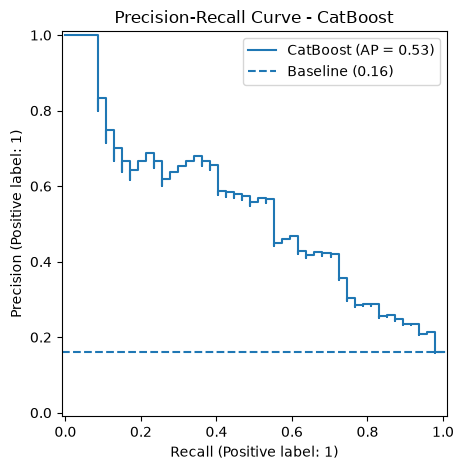

In [19]:
# ============================================================
# CELL 20: CATBOOST PRECISION-RECALL CURVE
# Mục đích: Phân tích khả năng phát hiện nhân viên nghỉ việc
# ============================================================

# Vẽ Precision-Recall Curve
PrecisionRecallDisplay.from_predictions(
    y_test,
    y_prob_catboost,
    name="CatBoost"
)

# Đường baseline theo tỷ lệ lớp nghỉ việc thực tế
baseline_rate = y_test.mean()

plt.axhline(
    y=baseline_rate,
    linestyle="--",
    label=f"Baseline ({baseline_rate:.2f})"
)

plt.title("Precision-Recall Curve - CatBoost")
plt.legend()

plt.tight_layout()
plt.show()

In [20]:
# ============================================================
# CELL 21: COMPARE MACHINE LEARNING MODELS
# Mục đích: So sánh hiệu suất Logistic Regression và CatBoost
# ============================================================

# Tạo bảng tổng hợp metrics của Logistic Regression và CatBoost
comparison_df = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "CatBoost"
    ],

    "Accuracy": [
        accuracy_logistic,
        accuracy_catboost
    ],

    "Precision": [
        precision_logistic,
        precision_catboost
    ],

    "Recall": [
        recall_logistic,
        recall_catboost
    ],

    "F1-score": [
        f1_logistic,
        f1_catboost
    ],

    "ROC-AUC": [
        roc_auc_logistic,
        roc_auc_catboost
    ],

    "PR-AUC": [
        pr_auc_logistic,
        pr_auc_catboost
    ]
})

# Làm tròn các chỉ số cho dễ đọc
comparison_df = comparison_df.round(4)

# Hiển thị bảng so sánh
display(comparison_df)

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC
0,Logistic Regression,0.8605,0.6154,0.3404,0.4384,0.8115,0.5836
1,CatBoost,0.8537,0.6667,0.1702,0.2712,0.8118,0.5327


In [21]:
# ============================================================
# CELL 21.1: BEST MODEL BY METRIC
# Mục đích: Xác định mô hình có giá trị tốt nhất theo từng metric
# ============================================================

# Các metrics cần so sánh
metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-score",
    "ROC-AUC",
    "PR-AUC"
]

# Duyệt qua từng metric
for metric in metrics:

    # Lấy tên mô hình có metric cao nhất
    best_model = comparison_df.loc[
        comparison_df[metric].idxmax(),
        "Model"
    ]

    # Lấy giá trị metric cao nhất
    best_score = comparison_df[metric].max()

    print(
        f"Best model for {metric}: "
        f"{best_model} ({best_score:.4f})"
    )

Best model for Accuracy: Logistic Regression (0.8605)
Best model for Precision: CatBoost (0.6667)
Best model for Recall: Logistic Regression (0.3404)
Best model for F1-score: Logistic Regression (0.4384)
Best model for ROC-AUC: CatBoost (0.8118)
Best model for PR-AUC: Logistic Regression (0.5836)


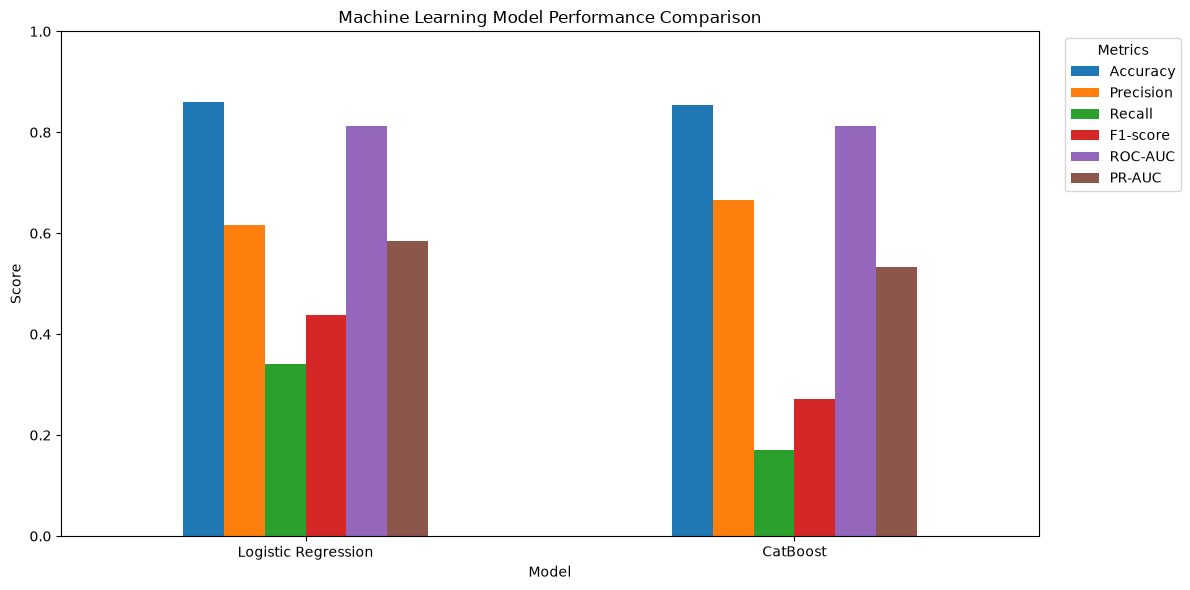

In [22]:
# ============================================================
# CELL 22: VISUALIZE MODEL COMPARISON
# Mục đích: Trực quan hóa hiệu suất của hai mô hình
# ============================================================

# Chọn các metrics để so sánh
metrics_to_plot = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-score",
    "ROC-AUC",
    "PR-AUC"
]

# Chuyển bảng sang dạng phù hợp cho biểu đồ
comparison_plot_df = comparison_df.set_index(
    "Model"
)[metrics_to_plot]

# Vẽ biểu đồ cột
comparison_plot_df.plot(
    kind="bar",
    figsize=(12, 6)
)

# Thiết lập tiêu đề và nhãn
plt.title("Machine Learning Model Performance Comparison")
plt.xlabel("Model")
plt.ylabel("Score")

# Trục tung từ 0 đến 1 vì các metrics đều là tỷ lệ
plt.ylim(0, 1)

# Xoay nhãn trục X
plt.xticks(rotation=0)

# Hiển thị chú giải
plt.legend(
    title="Metrics",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

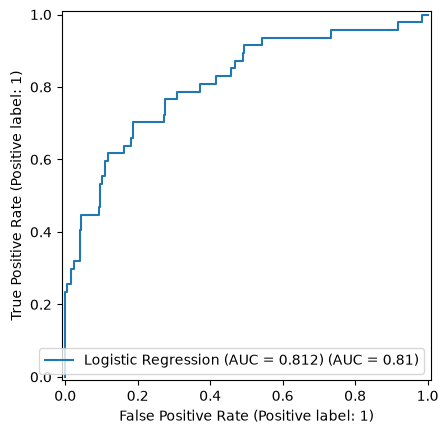

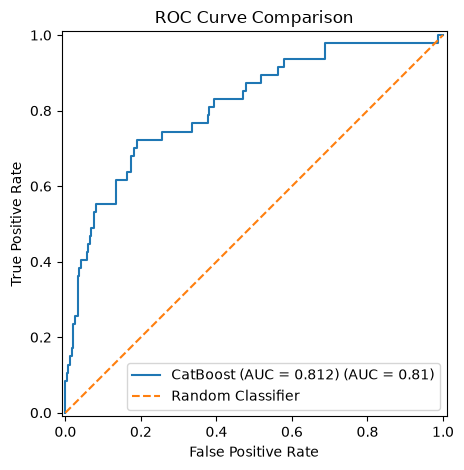

In [23]:
# ============================================================
# CELL 23: COMBINED ROC CURVE
# Mục đích: So sánh khả năng phân biệt của hai mô hình
# trên cùng một biểu đồ
# ============================================================

# Vẽ ROC Curve Logistic Regression
RocCurveDisplay.from_predictions(
    y_test,
    y_prob_logistic,
    name=f"Logistic Regression (AUC = {roc_auc_logistic:.3f})"
)

# Vẽ ROC Curve CatBoost trên cùng biểu đồ
RocCurveDisplay.from_predictions(
    y_test,
    y_prob_catboost,
    name=f"CatBoost (AUC = {roc_auc_catboost:.3f})"
)

# Vẽ đường phân loại ngẫu nhiên
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.title("ROC Curve Comparison")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.legend()
plt.tight_layout()
plt.show()

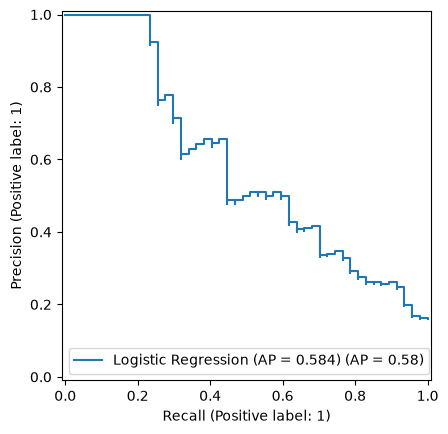

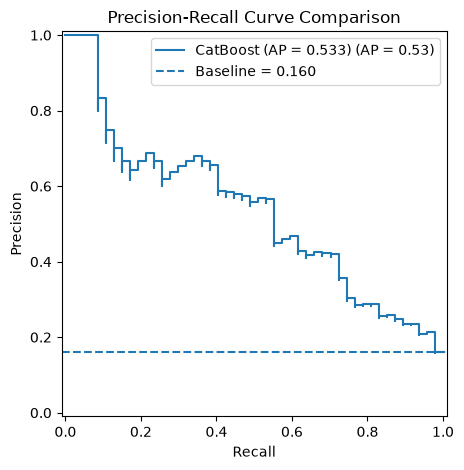

In [24]:
# ============================================================
# CELL 24: COMBINED PRECISION-RECALL CURVE
# Mục đích: So sánh khả năng nhận diện lớp nghỉ việc
# ============================================================

# Vẽ Precision-Recall Logistic Regression
PrecisionRecallDisplay.from_predictions(
    y_test,
    y_prob_logistic,
    name=f"Logistic Regression (AP = {pr_auc_logistic:.3f})"
)

# Vẽ Precision-Recall CatBoost
PrecisionRecallDisplay.from_predictions(
    y_test,
    y_prob_catboost,
    name=f"CatBoost (AP = {pr_auc_catboost:.3f})"
)

# Đường baseline của bài toán
baseline_rate = y_test.mean()

plt.axhline(
    y=baseline_rate,
    linestyle="--",
    label=f"Baseline = {baseline_rate:.3f}"
)

plt.title("Precision-Recall Curve Comparison")
plt.xlabel("Recall")
plt.ylabel("Precision")

plt.legend()
plt.tight_layout()
plt.show()

,Feature,Importance
12,JobRole,7.657336
18,OverTime,6.819856
0,Age,5.714884
15,MonthlyIncome,4.956132
17,NumCompaniesWorked,4.580416
7,EnvironmentSatisfaction,4.379120
1,BusinessTravel,4.161826
4,DistanceFromHome,4.055254
21,RelationshipSatisfaction,4.050114
22,StockOptionLevel,3.903977


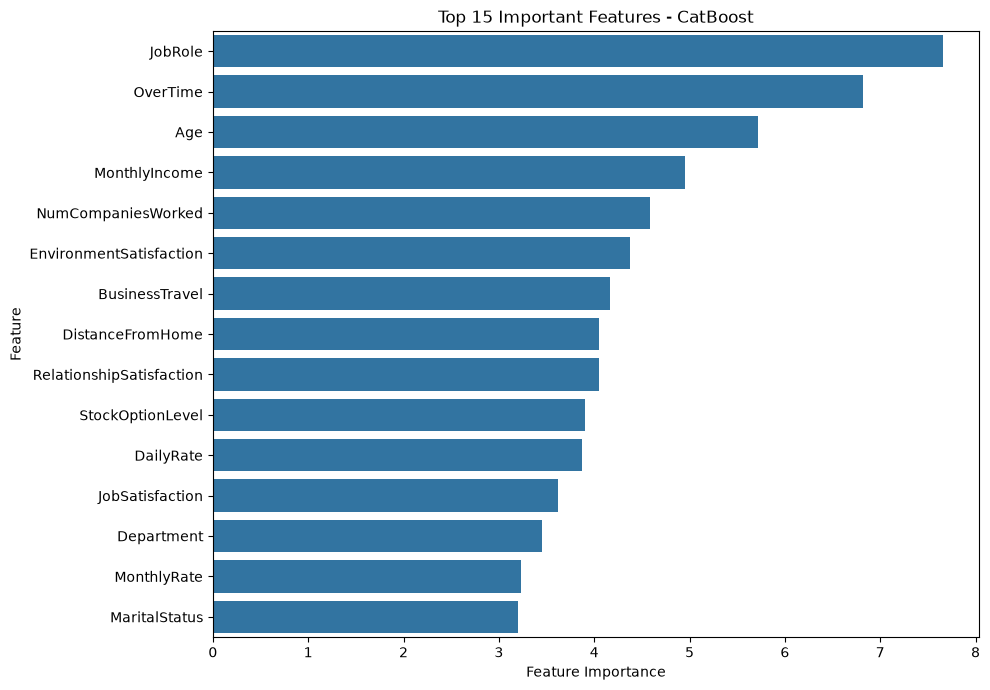

In [25]:
# ============================================================
# CELL 25: CATBOOST FEATURE IMPORTANCE
# Mục đích: Xác định những features quan trọng đối với CatBoost
# ============================================================

# Lấy mức độ quan trọng của các features từ CatBoost
feature_importance = catboost_model.get_feature_importance()

# Tạo DataFrame chứa tên features và importance score
feature_importance_df = pd.DataFrame({
    "Feature": X_train_cat.columns,
    "Importance": feature_importance
})

# Sắp xếp importance từ cao xuống thấp
feature_importance_df = feature_importance_df.sort_values(
    by="Importance",
    ascending=False
)

# Hiển thị bảng Feature Importance
display(feature_importance_df)

# Lấy Top 15 features quan trọng nhất
top_features = feature_importance_df.head(15)

# Vẽ biểu đồ Feature Importance
plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Important Features - CatBoost")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

In [26]:
# ============================================================
# CELL 26: SAVE ML RESULTS
# Mục đích: Lưu kết quả huấn luyện và đánh giá vào dự án
# ============================================================

# Tạo đường dẫn thư mục models và results
MODELS_DIR = PROJECT_DIR / "models"
RESULTS_DIR = PROJECT_DIR / "results"

# Tạo thư mục nếu chưa tồn tại
MODELS_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 1. LƯU BẢNG SO SÁNH MODEL
# ------------------------------------------------------------

# Lưu comparison_df thành file CSV
comparison_df.to_csv(
    RESULTS_DIR / "ml_model_comparison.csv",
    index=False
)

# ------------------------------------------------------------
# 2. LƯU FEATURE IMPORTANCE
# ------------------------------------------------------------

# Lưu Feature Importance thành CSV
feature_importance_df.to_csv(
    RESULTS_DIR / "catboost_feature_importance.csv",
    index=False
)

# ------------------------------------------------------------
# 3. LƯU PREDICTION RESULTS
# ------------------------------------------------------------

# Tạo DataFrame lưu kết quả dự đoán trên tập test
prediction_results = pd.DataFrame({
    "Actual": y_test.values,

    "Logistic_Predicted": y_pred_logistic,

    "Logistic_Probability": y_prob_logistic,

    "CatBoost_Predicted": y_pred_catboost,

    "CatBoost_Probability": y_prob_catboost
})

# Lưu kết quả dự đoán
prediction_results.to_csv(
    RESULTS_DIR / "ml_predictions.csv",
    index=False
)

# ------------------------------------------------------------
# 4. LƯU LOGISTIC REGRESSION
# ------------------------------------------------------------

# Lưu toàn bộ pipeline:
# Preprocessing + Logistic Regression
# Khi load lại sẽ không cần fit preprocessing từ đầu
joblib.dump(
    logistic_model,
    MODELS_DIR / "logistic_regression_pipeline.pkl"
)

# ------------------------------------------------------------
# 5. LƯU CATBOOST
# ------------------------------------------------------------

# Lưu CatBoost dưới định dạng native
catboost_model.save_model(
    str(MODELS_DIR / "catboost_model.cbm")
)

# ------------------------------------------------------------
# 6. THÔNG BÁO
# ------------------------------------------------------------

print("Results saved successfully!")

print("\nModels directory:")
print(MODELS_DIR)

print("\nResults directory:")
print(RESULTS_DIR)

Results saved successfully!

Models directory:
c:\Users\WINDOWS\Desktop\Project\project-data-analyst\Employee-Attrition-Prediction\models

Results directory:
c:\Users\WINDOWS\Desktop\Project\project-data-analyst\Employee-Attrition-Prediction\results


In [27]:
# ============================================================
# CELL 27: MACHINE LEARNING SUMMARY
# Mục đích: Tổng kết quá trình huấn luyện và đánh giá
# ============================================================

print("=" * 65)
print("EMPLOYEE ATTRITION PREDICTION - MACHINE LEARNING SUMMARY")
print("=" * 65)

# Dataset information
print("\nDataset:")
print("Total employees:", len(df))
print("Total features before cleaning:", df.shape[1])
print("Features after cleaning:", X.shape[1])

# Train/Test information
print("\nTrain/Test Split:")
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

# Model information
print("\nModels trained:")
print("1. Logistic Regression")
print("2. CatBoost")

# Metrics comparison
print("\nModel Performance:")
display(comparison_df)

# Best model theo F1-score
best_f1_model = comparison_df.loc[
    comparison_df["F1-score"].idxmax(),
    "Model"
]

print("\nBest model based on F1-score:")
print(best_f1_model)

# Best model theo Recall
best_recall_model = comparison_df.loc[
    comparison_df["Recall"].idxmax(),
    "Model"
]

print("\nBest model based on Recall:")
print(best_recall_model)

# Best model theo PR-AUC
best_pr_auc_model = comparison_df.loc[
    comparison_df["PR-AUC"].idxmax(),
    "Model"
]

print("\nBest model based on PR-AUC:")
print(best_pr_auc_model)

print("\nMachine Learning stage completed!")
print("=" * 65)

EMPLOYEE ATTRITION PREDICTION - MACHINE LEARNING SUMMARY

Dataset:
Total employees: 1470
Total features before cleaning: 35
Features after cleaning: 30

Train/Test Split:
Training samples: 1176
Testing samples: 294

Models trained:
1. Logistic Regression
2. CatBoost

Model Performance:


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC
0,Logistic Regression,0.8605,0.6154,0.3404,0.4384,0.8115,0.5836
1,CatBoost,0.8537,0.6667,0.1702,0.2712,0.8118,0.5327



Best model based on F1-score:
Logistic Regression

Best model based on Recall:
Logistic Regression

Best model based on PR-AUC:
Logistic Regression

Machine Learning stage completed!
